# Unit 8 Seminar: Recommender System
This notebook runs the supplied recommender exercise, Recommender_exercise.ipynb, which builds a collaborative filtering model with matrix factorisation on the MovieLens 100K ratings, then explains one prediction with SHAP. I ran it in Google Colab.

## Scope and corrections
I worked on a copy and kept the supplied text and code. I corrected one error: the ranking score NDCG@10 compared each list with an ideal built only from the hits already in that list, so it overstated ranking quality; it now uses every relevant film the user has. Nothing else in the supplied cells was changed.

After the supplied run I add five checks of my own: who the test set contains, the overfitting question the notebook asks, ranking against a simple popularity list, the size of the cold-user slice, and the brief's SHAP follow-up questions on a film I know is good and a film predicted low.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 03 November 2026 at 14:47 UTC


## Part 1: the supplied exercise (one correction)

In [2]:
#installing the required libraries. If not using Google Colab(recommended), make sure to check the requirements & versions

!pip install pandas numpy scikit-learn shap tqdm


In [3]:
# Load, examine and prepare dataset

import pandas as pd
import numpy as np
import zipfile
import io
import requests
from pathlib import Path


# Download MovieLens 100K
URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
DATA_DIR = Path("ml-100k")

if not DATA_DIR.exists():
    print("Downloading MovieLens 100K...")
    r = requests.get(URL)
    r.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        z.extractall()

print("Dataset ready.")

# If your network blocks downloads, requests.get() will fail.
# Check your connection and/or any other access issues.


# Load ratings
ratings = pd.read_csv(
    DATA_DIR / "u.data",
    sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"],
)


# Load items
items = pd.read_csv(
    DATA_DIR / "u.item",
    sep="|",
    encoding="latin-1",
    header=None
)

item_cols = (
    ["item_id", "title", "release_date", "video_release_date", "imdb_url"]
    + [f"genre_{i}" for i in range(19)]
)
items.columns = item_cols


# Validation & diagnostics
print(ratings.head())
print(items[["item_id", "title"]].head())

assert ratings["rating"].between(1, 5).all()
assert ratings["user_id"].nunique() <= 1000
assert ratings["item_id"].nunique() <= 1700

print("Ratings:", len(ratings))
print("Users:", ratings["user_id"].nunique())
print("Items:", ratings["item_id"].nunique())
print("Min/Max timestamp:", ratings["timestamp"].min(), ratings["timestamp"].max())

#Validation is essential. Recommenders are extremely sensitive to wrong/missing columns etc.
# REMEMBER: if your data is wrong, the model might still run, but your results will be meaningless

# Sparsity
# Sparsity measures how empty the user–movie matrix is, which can lead to less reliable recommendations.
# Most recommender datasets tend to be sparse, but this an important metrics to check.

n_users = ratings["user_id"].nunique()
n_items = ratings["item_id"].nunique()
sparsity = 1 - (len(ratings) / (n_users * n_items))
print(f"Sparsity: {sparsity:.4f}")

print("Rating distribution:")
print(ratings["rating"].value_counts().sort_index())


Dataset ready.
   user_id  item_id  rating  timestamp
0      196      242       3  881250949
1      186      302       3  891717742
2       22      377       1  878887116
3      244       51       2  880606923
4      166      346       1  886397596
   item_id              title
0        1   Toy Story (1995)
1        2   GoldenEye (1995)
2        3  Four Rooms (1995)
3        4  Get Shorty (1995)
4        5     Copycat (1995)
Ratings: 100000
Users: 943
Items: 1682
Min/Max timestamp: 874724710 893286638
Sparsity: 0.9370
Rating distribution:
rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


In [4]:
# Time-aware train/val/test split (80/10/10)
ratings_sorted = ratings.sort_values("timestamp").reset_index(drop=True)
n = len(ratings_sorted)

train = ratings_sorted.iloc[: int(0.8*n)]
val   = ratings_sorted.iloc[int(0.8*n): int(0.9*n)]
test  = ratings_sorted.iloc[int(0.9*n):]

assert train["timestamp"].max() <= val["timestamp"].min()
assert val["timestamp"].max() <= test["timestamp"].min()

print("\nSplit sizes:", len(train), len(val), len(test))

#Why time aware? In real life, you recommend based on the past, not the future.
# A random split can accidentally let the model “learn” patterns that rely on future interactions (data leakage).


Split sizes: 80000 10000 10000


In [5]:
# Build a Baseline Model.
# They are a benchmark against which more complex models can be evaluated.

from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np # Import numpy if not already imported, for np.sqrt

#Baselines (sanity checks)
def eval_constant(df, c):
    y_true = df["rating"].values.astype(float)
    y_pred = np.full_like(y_true, c, dtype=float)
    # Calculate MSE first, then take the square root for RMSE
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    return rmse, mae

global_mean = train["rating"].mean()
print("\nBaseline(global mean) VAL:", eval_constant(val, global_mean))
print("Baseline(global mean) TEST:", eval_constant(test, global_mean))

# Bias baseline: r_hat = mu + b_u + b_i (with regularization)
mu = train["rating"].mean()
lambda_reg = 10.0

user_sum = train.groupby("user_id")["rating"].sum()
user_cnt = train.groupby("user_id")["rating"].count()
item_sum = train.groupby("item_id")["rating"].sum()
item_cnt = train.groupby("item_id")["rating"].count()

b_u = ((user_sum - user_cnt * mu) / (user_cnt + lambda_reg)).to_dict()
b_i = ((item_sum - item_cnt * mu) / (item_cnt + lambda_reg)).to_dict()

def predict_bias(df):
    bu = df["user_id"].map(b_u).fillna(0.0).values
    bi = df["item_id"].map(b_i).fillna(0.0).values
    return mu + bu + bi

def eval_model(df, pred_fn):
    y_true = df["rating"].values.astype(float)
    y_pred = pred_fn(df).astype(float)
    # Calculate MSE first, then take the square root for RMSE
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    return rmse, mae

print("\nBias baseline VAL:", eval_model(val, predict_bias))
print("\nBias baseline TEST:", eval_model(test, predict_bias))

# Bias account for people's different approach.
# Expected outcome: bias baseline should beat global mean baseline.


Baseline(global mean) VAL: (np.float64(1.0979175162552057), 0.92612078)
Baseline(global mean) TEST: (np.float64(1.1399315560593977), 0.96937963)

Bias baseline VAL: (np.float64(1.0191052016857545), 0.810877103220018)

Bias baseline TEST: (np.float64(1.0446204580678322), 0.8480805896543465)


In [6]:
# Matrix Factorization assumes each user and each movie can be described by hidden features
#We don’t label these features. The model discovers them automatically.

import numpy as np
from tqdm import trange

# Define the mapping function to convert user/item IDs to contiguous indices
user_ids = sorted(ratings["user_id"].unique())
item_ids = sorted(ratings["item_id"].unique())

user_to_idx = {user_id: idx for idx, user_id in enumerate(user_ids)}
item_to_idx = {item_id: idx for idx, item_id in enumerate(item_ids)}

def to_idx(df):
    u_idx = df["user_id"].map(user_to_idx).values
    m_idx = df["item_id"].map(item_to_idx).values
    r = df["rating"].values
    return u_idx, m_idx, r

#Matrix Factorization (SGD==stochastic gradient descent)

train_u, train_m, train_r = to_idx(train)
val_u,   val_m,   val_r   = to_idx(val)
test_u,  test_m,  test_r  = to_idx(test)

n_users = len(user_ids)
n_items = len(item_ids)

rng = np.random.default_rng(42)
k = 32
lr = 0.01
reg = 0.02
epochs = 30

mu_mf = train_r.mean()
bu = np.zeros(n_users)
bi = np.zeros(n_items)
P = 0.1 * rng.standard_normal((n_users, k))
Q = 0.1 * rng.standard_normal((n_items, k))

def mf_predict(u_idx, m_idx):
    return mu_mf + bu[u_idx] + bi[m_idx] + np.sum(P[u_idx] * Q[m_idx], axis=1)

def rmse_vec(y_true, y_pred):
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

history = []
print("\nTraining MF...")
for epoch in trange(1, epochs + 1):
    perm = rng.permutation(len(train_r))
    u_sh, m_sh, r_sh = train_u[perm], train_m[perm], train_r[perm]

    for u, m, r in zip(u_sh, m_sh, r_sh):
        pred = mu_mf + bu[u] + bi[m] + P[u].dot(Q[m])
        err = r - pred

        bu[u] += lr * (err - reg * bu[u])
        bi[m] += lr * (err - reg * bi[m])

        pu = P[u].copy()
        qi = Q[m].copy()
        P[u] += lr * (err * qi - reg * pu)
        Q[m] += lr * (err * pu - reg * qi)

    train_rmse = rmse_vec(train_r, mf_predict(train_u, train_m))
    val_rmse   = rmse_vec(val_r,   mf_predict(val_u,   val_m))
    history.append((epoch, train_rmse, val_rmse))

    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | train RMSE={train_rmse:.4f} | val RMSE={val_rmse:.4f}")

test_pred = mf_predict(test_u, test_m)
test_rmse = rmse_vec(test_r, test_pred)
test_mae  = float(np.mean(np.abs(test_r - test_pred)))
print("\nMF TEST RMSE:", test_rmse, " MAE:", test_mae)


Training MF...


  3%|▎         | 1/30 [00:04<02:20,  4.84s/it]

Epoch 01 | train RMSE=0.9554 | val RMSE=1.0388


 17%|█▋        | 5/30 [00:20<01:30,  3.62s/it]

Epoch 05 | train RMSE=0.8905 | val RMSE=1.0301


 33%|███▎      | 10/30 [00:28<00:37,  1.90s/it]

... (5 outputs left out)

 83%|████████▎ | 25/30 [00:56<00:08,  1.63s/it]

Epoch 25 | train RMSE=0.5813 | val RMSE=1.0404


100%|██████████| 30/30 [01:05<00:00,  2.17s/it]

Epoch 30 | train RMSE=0.5458 | val RMSE=1.0429

MF TEST RMSE: 1.0399901844123336  MAE: 0.8358307064794833


It is important here to look at your results.
Training diagnostics: train RMSE vs val RMSE
If both go down → good.
BUT
If train goes down but val goes up → overfitting.
Is it the case here? Check.
If you detect overfitting, one simple fix is to stop early (fewer epochs) in your training routine.

In [7]:
# Top-N recommendations + ranking validation
#Why do we use a ranking metric? Because of what the RS do.
# They are judged on their usefulness: “Did we put the right movies near the top?”


train_items_by_user = train.groupby("user_id")["item_id"].apply(set).to_dict()
test_pos = test[test["rating"] >= 4].groupby("user_id")["item_id"].apply(set).to_dict()

all_item_idx = np.arange(n_items)

u2i = user_to_idx # Alias user_to_idx to u2i
m2i = item_to_idx # Alias item_to_idx to m2i

def ndcg_at_k(relevances, k, n_relevant):
    # Corrected: the ideal list holds every relevant film the user has (up to k),
    # not only the hits that were already in the top k. The supplied version
    # sorted the top-k hits, so a list with one hit at the top scored as perfect.
    rel = relevances[:k]
    dcg = sum((2**r - 1) / np.log2(i + 2) for i, r in enumerate(rel))
    ideal = [1] * min(n_relevant, k)
    idcg = sum((2**r - 1) / np.log2(i + 2) for i, r in enumerate(ideal))
    return 0.0 if idcg == 0 else float(dcg / idcg)

def recommend_for_user(user_id, K=10):
    uidx = u2i[user_id]
    seen = train_items_by_user.get(user_id, set())
    seen_idx = np.array([m2i[m] for m in seen if m in m2i], dtype=int)

    u_vec = np.full(n_items, uidx, dtype=int)
    scores = mf_predict(u_vec, all_item_idx)

    scores[seen_idx] = -1e9  # filter seen items

    topk_idx = np.argpartition(-scores, K)[:K]
    topk_idx = topk_idx[np.argsort(-scores[topk_idx])]

    topk_item_ids = [item_ids[i] for i in topk_idx]
    return topk_item_ids, scores[topk_idx]

def ranking_eval(K=10, max_users=500):
    users = list(test["user_id"].unique())[:max_users]
    precs, recs, ndcgs, cover_items = [], [], [], set()

    for u in users:
        gt = test_pos.get(u, set())
        if not gt:
            continue

        recs_u, _ = recommend_for_user(u, K=K)
        cover_items.update(recs_u)

        hits = [1 if m in gt else 0 for m in recs_u]
        precs.append(np.mean(hits))
        recs.append(np.sum(hits) / len(gt))
        ndcgs.append(ndcg_at_k(hits, K, len(gt)))

    coverage = len(cover_items) / n_items
    return {
        "precision@k": float(np.mean(precs)) if precs else 0.0,
        "recall@k": float(np.mean(recs)) if recs else 0.0,
        "ndcg@k": float(np.mean(ndcgs)) if ndcgs else 0.0,
        "item_coverage": float(coverage),
        "users_evaluated": int(len(precs))
    }

print("\nRanking metrics:", ranking_eval(K=10))


Ranking metrics: {'precision@k': 0.14183006535947715, 'recall@k': 0.051162096261366884, 'ndcg@k': 0.1490062510401981, 'item_coverage': 0.14625445897740785, 'users_evaluated': 153}


Metrics explained:

Precision@K: among the top K recommendations, what fraction are relevant?

Recall@K: among the relevant items the user had, what fraction did we retrieve in top K?

NDCG@K: like precision but rewards correct items appearing earlier in the list (higher rank is better).

Item coverage: how many distinct items appear in recommendations across users.

Low coverage means the model recommends the same popular movies to everyone.

In [8]:
# Diagnostics: cold-start slices + popularity bias proxy
# It is important to classify the users in RS
# Users with few ratings are hard (COLD USERS): not enough data to learn a stable preference vector
# This is why we compute RMSE separately.

user_counts = train.groupby("user_id")["rating"].count()

def slice_users(min_ratings, max_ratings=None):
    if max_ratings is None:
        return set(user_counts[user_counts >= min_ratings].index)
    return set(user_counts[(user_counts >= min_ratings) & (user_counts <= max_ratings)].index)

cold_users = slice_users(1, 10)
warm_users = slice_users(50, None)

def rmse_on_user_subset(df, user_set):
    df2 = df[df["user_id"].isin(user_set)]
    if len(df2) == 0:
        return None
    u, m, r = to_idx(df2)
    pred = mf_predict(u, m)
    return rmse_vec(r, pred)

print("\nRMSE test cold users (1-10 ratings):", rmse_on_user_subset(test, cold_users))
print("RMSE test warm users (>=50 ratings):", rmse_on_user_subset(test, warm_users))

item_pop = train.groupby("item_id")["rating"].count().to_dict()

def avg_popularity_of_recs(sample_users=200, K=10):
    users = list(test["user_id"].unique())[:sample_users]
    pops = []
    for u in users:
        recs_u, _ = recommend_for_user(u, K=K)
        pops.extend([item_pop.get(m, 0) for m in recs_u])
    return float(np.mean(pops)), float(np.median(pops))

print("Avg/Median popularity of recs:", avg_popularity_of_recs())


RMSE test cold users (1-10 ratings): 1.2365472979247374
RMSE test warm users (>=50 ratings): 1.0095493780701932
Avg/Median popularity of recs: (159.83072289156627, 148.0)


In [9]:
from sklearn.linear_model import Ridge
import shap

# Explainable AI (SHAP) for MF prediction
def mf_feature_matrix(u_idx, m_idx):
    inter = P[u_idx] * Q[m_idx]  # (n, k)
    return np.column_stack([bu[u_idx], bi[m_idx], inter])

# Surrogate training sample (approximate MF behavior)
N_SAMPLE = 20000
idx = rng.choice(len(train_r), size=min(N_SAMPLE, len(train_r)), replace=False)

X_surr = mf_feature_matrix(train_u[idx], train_m[idx])
y_surr = mf_predict(train_u[idx], train_m[idx])

surr = Ridge(alpha=1.0)
surr.fit(X_surr, y_surr)

pred_check = surr.predict(X_surr)
print("\nSurrogate fidelity RMSE (surrogate vs MF):", rmse_vec(y_surr, pred_check))

# SHAP for linear surrogate
explainer = shap.LinearExplainer(surr, X_surr, feature_perturbation="interventional")
feature_names = ["user_bias", "item_bias"] + [f"latent_inter_{j}" for j in range(k)]

def explain_prediction(user_id, item_id, top_n=10):
    uidx = u2i[user_id]
    midx = m2i[item_id]

    x = mf_feature_matrix(np.array([uidx]), np.array([midx]))
    pred_mf = float(mf_predict(np.array([uidx]), np.array([midx]))[0])
    pred_surr = float(surr.predict(x)[0])

    shap_vals = explainer.shap_values(x)[0]
    base = float(explainer.expected_value)

    title = items.loc[items["item_id"] == item_id, "title"].values
    title = title[0] if len(title) else str(item_id)

    contribs = list(zip(feature_names, shap_vals))
    contribs.sort(key=lambda t: abs(t[1]), reverse=True)

    print(f"\nExplanation for: User {user_id} -> Movie {item_id} ({title})")
    print(f"MF prediction:        {pred_mf:.3f}")
    print(f"Surrogate prediction: {pred_surr:.3f}")
    print(f"SHAP base value:      {base:.3f}")
    print("Top SHAP contributions:")
    for name, val in contribs[:top_n]:
        print(f"  {name:>16}: {val:+.4f}")

    return shap_vals, x

# Example explanation on a real test row
row = test.iloc[0]
_ = explain_prediction(int(row.user_id), int(row.item_id), top_n=10)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)



Surrogate fidelity RMSE (surrogate vs MF): 0.0027011449127618934

Explanation for: User 90 -> Movie 900 (Kundun (1997))
MF prediction:        3.928
Surrogate prediction: 3.929
SHAP base value:      3.518
Top SHAP contributions:
         item_bias: +0.2410
         user_bias: +0.1587
   latent_inter_13: -0.0328
   latent_inter_24: +0.0310
    latent_inter_3: +0.0225
   latent_inter_17: -0.0217
   latent_inter_16: +0.0210
   latent_inter_11: +0.0180
   latent_inter_28: -0.0178
    latent_inter_0: -0.0175


Matrix Factorization predicts a rating using internal parameters (biases and latent vectors), not using explicit  “features” like genre or age.
SHAP, however, explains predictions by attributing them to input features. Because MF does not naturally expose such features, we re-express each MF prediction as a feature vector built from its own components, then train a simple model to reproduce MF’s output. SHAP is applied to this simple model, allowing us to explain which parts of the MF prediction mattered most. The surrogate is a simple, interpretable model that imitates the behaviour of a more complex model so that we can explain its predictions.
The whole idea is that we can EXPLAIN the results we got with MF using a more transparent approach (==explanaible AI)


## Part 2: my checks
The cells below reuse the data, split and trained model from Part 1, so Part 1 must be run first.

In [10]:
import json, time
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path.cwd() / "Unit8_Seminar_Exports"
OUT.mkdir(exist_ok=True)
results = {}
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

versions = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "shap": shap.__version__, "matplotlib": matplotlib.__version__}
print("Package versions:", versions)
results["versions"] = versions

Package versions: {'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'shap': '0.54.1', 'matplotlib': '3.10.0'}


### Check 1: who is in the test set
The split is by time, so the test set holds the last 10% of ratings. Some of those ratings may come from users who joined after the training period. The model has never seen them: their user bias stays at 0 and their hidden vector stays at its random starting value.

In [11]:
train_users = set(train["user_id"])
for name, df in [("Validation", val), ("Test", test)]:
    new_users = set(df["user_id"]) - train_users
    rows_new = int(df["user_id"].isin(new_users).sum())
    print(f"{name}: {df['user_id'].nunique()} users, {len(new_users)} with no training ratings; "
          f"{rows_new} of {len(df)} ratings come from them")
    results[f"{name.lower()}_users"] = int(df["user_id"].nunique())
    results[f"{name.lower()}_new_users"] = len(new_users)
    results[f"{name.lower()}_rows_from_new_users"] = rows_new

test_new_users = set(test["user_id"]) - train_users
seen_mask = ~test["user_id"].isin(test_new_users).values

def rmse_parts(y_true, y_pred):
    return {"all": rmse_vec(y_true, y_pred),
            "seen users": rmse_vec(y_true[seen_mask], y_pred[seen_mask]),
            "new users": rmse_vec(y_true[~seen_mask], y_pred[~seen_mask])}

y_test = test["rating"].values.astype(float)
by_part = {
    "Global mean": rmse_parts(y_test, np.full_like(y_test, global_mean)),
    "Bias baseline": rmse_parts(y_test, predict_bias(test)),
    "Matrix factorisation (30 epochs)": rmse_parts(y_test, mf_predict(test_u, test_m)),
}
table = pd.DataFrame(by_part).T.round(4)
print("\nTest RMSE by group of users:")
print(table)
results["test_rmse_by_group"] = table.to_dict(orient="index")

# Ratings run from 1 to 5, but the model's predictions are not limited to that range
p30 = mf_predict(test_u, test_m)
outside = float(np.mean((p30 < 1) | (p30 > 5)))
clipped = rmse_vec(test_r, np.clip(p30, 1, 5))
print(f"\nTest predictions outside 1 to 5: {outside:.2%}; test RMSE {rmse_vec(test_r, p30):.4f}, "
      f"or {clipped:.4f} if clipped to the scale")
results["share_outside_scale"] = outside
results["test_rmse_clipped"] = clipped

Validation: 197 users, 116 with no training ratings; 8466 of 10000 ratings come from them
Test: 166 users, 97 with no training ratings; 8582 of 10000 ratings come from them

Test RMSE by group of users:
                                     all  seen users  new users
Global mean                       1.1399      1.1914     1.1312
Bias baseline                     1.0446      1.1193     1.0318
Matrix factorisation (30 epochs)  1.0400      1.0233     1.0427

Test predictions outside 1 to 5: 0.25%; test RMSE 1.0400, or 1.0399 if clipped to the scale


### Check 2: the overfitting question
The supplied text asks whether training error falls while validation error rises. The history recorded during training answers it. I then retrain with the number of epochs that gave the lowest validation error (early stopping, as the supplied text suggests), keeping the supplied settings and seed, and time both models.

 epoch  train_rmse  val_rmse
     1      0.9554    1.0388
     5      0.8905    1.0301
    10      0.8089    1.0320
    15      0.7112    1.0346
    20      0.6338    1.0381
    25      0.5813    1.0404
    30      0.5458    1.0429

Lowest validation RMSE: 1.0301 at epoch 5; at epoch 30 it is 1.0429


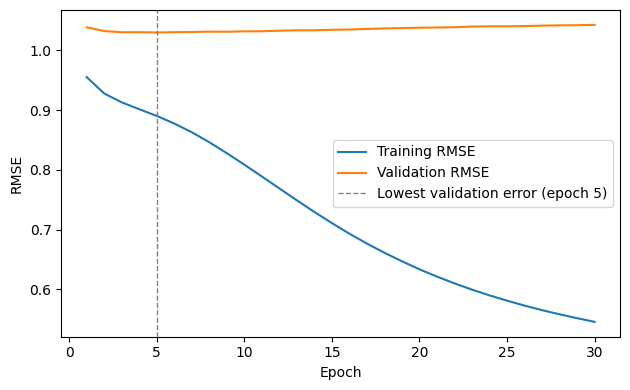

In [12]:
hist = pd.DataFrame(history, columns=["epoch", "train_rmse", "val_rmse"])
best = hist.loc[hist["val_rmse"].idxmin()]
print(hist.iloc[[0, 4, 9, 14, 19, 24, 29]].round(4).to_string(index=False))
print(f"\nLowest validation RMSE: {best.val_rmse:.4f} at epoch {int(best.epoch)}; "
      f"at epoch 30 it is {hist.val_rmse.iloc[-1]:.4f}")
results["best_epoch"] = int(best.epoch)
results["best_val_rmse"] = float(best.val_rmse)
results["epoch30_val_rmse"] = float(hist.val_rmse.iloc[-1])
results["epoch1_train_rmse"] = float(hist.train_rmse.iloc[0])
results["epoch30_train_rmse"] = float(hist.train_rmse.iloc[-1])

plt.figure(figsize=(6.4, 4))
plt.plot(hist.epoch, hist.train_rmse, label="Training RMSE")
plt.plot(hist.epoch, hist.val_rmse, label="Validation RMSE")
plt.axvline(int(best.epoch), color="grey", linestyle="--", linewidth=1, label=f"Lowest validation error (epoch {int(best.epoch)})")
plt.xlabel("Epoch"); plt.ylabel("RMSE"); plt.legend(); plt.tight_layout()
plt.savefig(OUT / "train_vs_validation_rmse.png", dpi=180, bbox_inches="tight")
plt.show()

In [13]:
def train_mf_copy(n_epochs, seed=42):
    # Same settings and seed as the supplied cell, but kept in separate arrays
    # so that the supplied 30-epoch model used by SHAP is not overwritten.
    g = np.random.default_rng(seed)
    bu_c, bi_c = np.zeros(n_users), np.zeros(n_items)
    P_c = 0.1 * g.standard_normal((n_users, k))
    Q_c = 0.1 * g.standard_normal((n_items, k))
    for _ in range(n_epochs):
        perm = g.permutation(len(train_r))
        for u, m, r in zip(train_u[perm], train_m[perm], train_r[perm]):
            err = r - (mu_mf + bu_c[u] + bi_c[m] + P_c[u].dot(Q_c[m]))
            bu_c[u] += lr * (err - reg * bu_c[u])
            bi_c[m] += lr * (err - reg * bi_c[m])
            pu, qi = P_c[u].copy(), Q_c[m].copy()
            P_c[u] += lr * (err * qi - reg * pu)
            Q_c[m] += lr * (err * pu - reg * qi)
    return bu_c, bi_c, P_c, Q_c

t0 = time.perf_counter()
bu_s, bi_s, P_s, Q_s = train_mf_copy(int(best.epoch))
mf_seconds = time.perf_counter() - t0

def mf_stop_predict(u_idx, m_idx):
    return mu_mf + bu_s[u_idx] + bi_s[m_idx] + np.sum(P_s[u_idx] * Q_s[m_idx], axis=1)

# The supplied seed and order are reused, so this retrain should match epoch
# best.epoch of the supplied run exactly.
check = rmse_vec(val_r, mf_stop_predict(val_u, val_m))
print(f"Retrained validation RMSE: {check:.4f} (history at that epoch: {best.val_rmse:.4f})")

# Time the whole bias fit, as in the supplied cell: sums, counts and the two formulas
t0 = time.perf_counter()
_mu = train["rating"].mean()
_us, _uc = train.groupby("user_id")["rating"].sum(), train.groupby("user_id")["rating"].count()
_is, _ic = train.groupby("item_id")["rating"].sum(), train.groupby("item_id")["rating"].count()
_bu = ((_us - _uc * _mu) / (_uc + lambda_reg)).to_dict()
_bi = ((_is - _ic * _mu) / (_ic + lambda_reg)).to_dict()
bias_seconds = time.perf_counter() - t0

y_val = val["rating"].values.astype(float)
compare = pd.DataFrame({
    "Bias baseline": {"val RMSE": rmse_vec(y_val, predict_bias(val)), "test RMSE": rmse_vec(y_test, predict_bias(test)),
                      "seen-user test RMSE": by_part["Bias baseline"]["seen users"], "fit time (s)": bias_seconds},
    "MF, 30 epochs (supplied)": {"val RMSE": rmse_vec(val_r, mf_predict(val_u, val_m)), "test RMSE": rmse_vec(test_r, mf_predict(test_u, test_m)),
                                 "seen-user test RMSE": by_part["Matrix factorisation (30 epochs)"]["seen users"],
                                 "fit time (s)": float("nan")},
    f"MF, {int(best.epoch)} epochs (early stop)": {"val RMSE": check, "test RMSE": rmse_vec(test_r, mf_stop_predict(test_u, test_m)),
                                 "seen-user test RMSE": rmse_vec(test_r[seen_mask], mf_stop_predict(test_u, test_m)[seen_mask]),
                                 "fit time (s)": mf_seconds},
}).T
print("\n", compare.round(4))
print(f"\nMF training time per epoch: about {mf_seconds / int(best.epoch):.2f} s")
results["model_comparison"] = compare.round(6).to_dict(orient="index")
results["mf_seconds_per_epoch"] = mf_seconds / int(best.epoch)

Retrained validation RMSE: 1.0301 (history at that epoch: 1.0301)

                            val RMSE  test RMSE  seen-user test RMSE  fit time (s)
Bias baseline                1.0191     1.0446               1.1193        0.0137
MF, 30 epochs (supplied)     1.0429     1.0400               1.0233           NaN
MF, 5 epochs (early stop)    1.0301     1.0370               1.0250        9.4174

MF training time per epoch: about 1.88 s


### Check 3: ranking against a simple popularity list
I compare the supplied model's top-10 lists with a list of the most-rated films the user has not seen, using the corrected NDCG, and keep the supplied formula alongside so the size of the correction is visible. I also split the users into those with and without training ratings.

In [14]:
def ndcg_supplied(relevances, k):
    # The supplied formula, kept only to show the size of the correction
    rel = relevances[:k]
    dcg = sum((2**r - 1) / np.log2(i + 2) for i, r in enumerate(rel))
    ideal = sorted(relevances, reverse=True)[:k]
    idcg = sum((2**r - 1) / np.log2(i + 2) for i, r in enumerate(ideal))
    return 0.0 if idcg == 0 else float(dcg / idcg)

pop_scores = np.array([item_pop.get(m, 0) for m in item_ids], dtype=float)

def top_k(user_id, scores, K=10):
    scores = scores.copy()
    seen = train_items_by_user.get(user_id, set())
    scores[[m2i[m] for m in seen if m in m2i]] = -1e9
    idx = np.argpartition(-scores, K)[:K]
    idx = idx[np.argsort(-scores[idx])]
    return [item_ids[i] for i in idx]

def mf_scores(user_id):
    return mf_predict(np.full(n_items, u2i[user_id], dtype=int), all_item_idx)

def evaluate(score_fn, users, K=10):
    precs, recs, nd, nd_old, cover = [], [], [], [], set()
    for u in users:
        gt = test_pos.get(u, set())
        if not gt:
            continue
        r = top_k(u, score_fn(u), K)
        cover.update(r)
        hits = [1 if m in gt else 0 for m in r]
        precs.append(np.mean(hits)); recs.append(sum(hits) / len(gt))
        nd.append(ndcg_at_k(hits, K, len(gt))); nd_old.append(ndcg_supplied(hits, K))
    return {"users": len(precs), "precision@10": np.mean(precs), "recall@10": np.mean(recs),
            "NDCG@10": np.mean(nd), "NDCG@10 (supplied formula)": np.mean(nd_old),
            "item coverage": len(cover) / n_items}

eval_users = list(test["user_id"].unique())[:500]   # the supplied ranking uses these users
groups = {"all": eval_users,
          "seen users": [u for u in eval_users if u in train_users],
          "new users": [u for u in eval_users if u not in train_users]}
rank_rows = {}
for gname, users in groups.items():
    rank_rows[f"MF, {gname}"] = evaluate(mf_scores, users)
    rank_rows[f"Popularity, {gname}"] = evaluate(lambda u: pop_scores, users)
rank_table = pd.DataFrame(rank_rows).T
print(rank_table.round(4))
results["ranking"] = rank_table.round(6).to_dict(orient="index")

                        users  precision@10  recall@10  NDCG@10  NDCG@10 (supplied formula)  item coverage
MF, all                 153.0        0.1418     0.0512   0.1490                      0.3040         0.1463
Popularity, all         153.0        0.1902     0.0655   0.2087                      0.4110         0.0446
MF, seen users           57.0        0.0579     0.0716   0.0790                      0.1614         0.1427
Popularity, seen users   57.0        0.0912     0.0478   0.1041                      0.2071         0.0446
MF, new users            96.0        0.1917     0.0390   0.1905                      0.3887         0.0559
Popularity, new users    96.0        0.2490     0.0760   0.2707                      0.5321         0.0059


### Check 4: how many users the cold-user slice holds
The supplied diagnostics report a separate error for cold users (1 to 10 training ratings). The number of test users and ratings behind that figure decides how much it can tell us.

In [15]:
for name, users in [("Cold (1-10 training ratings)", cold_users), ("Warm (50 or more)", warm_users)]:
    rows = test[test["user_id"].isin(users)]
    print(f"{name}: {rows['user_id'].nunique()} test users, {len(rows)} test ratings")
    results[f"slice_{name.split()[0].lower()}"] = {"test_users": int(rows["user_id"].nunique()), "test_ratings": int(len(rows))}
print(f"Users with no training ratings: {len(test_new_users)} test users, {int((~seen_mask).sum())} test ratings")

Cold (1-10 training ratings): 1 test users, 36 test ratings
Warm (50 or more): 60 test users, 1256 test ratings
Users with no training ratings: 97 test users, 8582 test ratings


### Check 5: the SHAP follow-up questions
The surrogate is a linear model whose inputs are the parts the matrix factorisation model adds together: user bias, film bias and the 32 products of the hidden vectors. First I look at what the surrogate learnt, and at the user in the supplied example.

Then, for one user the model has learnt from, I explain two predictions, as the brief asks: a film I know is good, and the film predicted lowest for that user among films with at least 20 training ratings (my threshold, so that the film's bias rests on more than a handful of ratings). To judge whether each explanation makes sense, I print the facts it should reflect: the user's average rating and the film's average rating in the training data.

In [16]:
print("Surrogate intercept:", round(float(surr.intercept_), 4))
print("Surrogate weights for user bias, film bias and the first three hidden products:",
      np.round(surr.coef_[:5], 4))
results["surrogate_coef_first5"] = [float(c) for c in surr.coef_[:5]]
results["surrogate_fidelity_rmse"] = rmse_vec(y_surr, pred_check)

ex = test.iloc[0]
n_train_ex = int(user_cnt.get(int(ex.user_id), 0))
print(f"\nSupplied example: user {int(ex.user_id)} has {n_train_ex} training ratings; "
      f"their user bias in the model is {bu[u2i[int(ex.user_id)]]:.4f}")
print(f"Average user bias in the surrogate's sample: {X_surr[:, 0].mean():.4f}")
results["supplied_example"] = {"user_id": int(ex.user_id), "item_id": int(ex.item_id),
                               "train_ratings": n_train_ex, "user_bias": float(bu[u2i[int(ex.user_id)]]),
                               "mean_user_bias_in_sample": float(X_surr[:, 0].mean())}

Surrogate intercept: 3.5178
Surrogate weights for user bias, film bias and the first three hidden products: [0.9997 1.0001 0.9963 0.9947 0.9946]

Supplied example: user 90 has 0 training ratings; their user bias in the model is 0.0000
Average user bias in the surrogate's sample: -0.1510


In [17]:
GOOD_TITLE = "Blade Runner (1982)"   # a film I know is good; change the title here to test another

good_item = int(items.loc[items["title"] == GOOD_TITLE, "item_id"].iloc[0])
seen_test_users = [u for u in test["user_id"].unique() if u in train_users]
# The seen test user with the most training ratings, so the model has learnt their taste
user = int(max(seen_test_users, key=lambda u: user_cnt.get(u, 0)))

film_stats = train.groupby("item_id")["rating"].agg(["mean", "count"])
eligible = film_stats[film_stats["count"] >= 20].index
scores_user = mf_scores(user)
low_item = int(min(eligible, key=lambda m: scores_user[m2i[m]]))

print(f"User {user}: {int(user_cnt[user])} training ratings, average {train[train.user_id == user].rating.mean():.2f} "
      f"(all users: {mu:.2f})")
shap_cases = {}
for label, item in [("good", good_item), ("low", low_item)]:
    vals, x = explain_prediction(user, item, top_n=6)
    st = film_stats.loc[item] if item in film_stats.index else None
    print(f"  Film's training ratings: {int(st['count']) if st is not None else 0}, "
          f"average {st['mean']:.2f}" if st is not None else "  Film has no training ratings")
    actual = test[(test.user_id == user) & (test.item_id == item)]["rating"]
    seen_before = item in train_items_by_user.get(user, set())
    train_rating = train[(train.user_id == user) & (train.item_id == item)]["rating"]
    print(f"  This user's rating in training: {int(train_rating.iloc[0]) if len(train_rating) else 'none'}; "
          f"in the test set: {int(actual.iloc[0]) if len(actual) else 'none'}")
    latent_sum = float(np.sum(vals[2:]))
    print(f"  SHAP from user bias {vals[0]:+.4f}, film bias {vals[1]:+.4f}, all 32 hidden products together {latent_sum:+.4f}")
    shap_cases[label] = {"item_id": item, "title": items.loc[items.item_id == item, "title"].iloc[0],
                         "mf_prediction": float(mf_predict(np.array([u2i[user]]), np.array([m2i[item]]))[0]),
                         "shap_user_bias": float(vals[0]), "shap_item_bias": float(vals[1]),
                         "shap_latent_total": latent_sum,
                         "film_train_count": int(st["count"]) if st is not None else 0,
                         "film_train_mean": float(st["mean"]) if st is not None else None,
                         "rated_in_train": bool(seen_before),
                         "train_rating": int(train_rating.iloc[0]) if len(train_rating) else None,
                         "test_rating": int(actual.iloc[0]) if len(actual) else None}
results["shap_user"] = {"user_id": user, "train_ratings": int(user_cnt[user]),
                        "train_mean": float(train[train.user_id == user].rating.mean())}
results["shap_cases"] = shap_cases
results["shap_base_value"] = float(explainer.expected_value)

User 13: 608 training ratings, average 3.11 (all users: 3.52)

Explanation for: User 13 -> Movie 89 (Blade Runner (1982))
MF prediction:        3.803
Surrogate prediction: 3.804
SHAP base value:      3.518
Top SHAP contributions:
         item_bias: +0.4243
   latent_inter_10: -0.3552
   latent_inter_12: +0.3159
   latent_inter_21: +0.2758
    latent_inter_7: -0.2606
   latent_inter_17: -0.2431
  Film's training ratings: 223, average 4.12
  This user's rating in training: 4; in the test set: none
  SHAP from user bias -0.1720, film bias +0.4243, all 32 hidden products together +0.0332

Explanation for: User 13 -> Movie 368 (Bio-Dome (1996))
MF prediction:        0.301
Surrogate prediction: 0.307
SHAP base value:      3.518
Top SHAP contributions:
         item_bias: -1.6809
   latent_inter_12: -0.3271
   latent_inter_21: -0.2646
   latent_inter_13: -0.2219
   latent_inter_30: -0.2014
   latent_inter_31: -0.2002
  Film's training ratings: 28, average 1.89
  This user's rating in trainin

In [18]:
with open(OUT / "results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("Saved:", sorted(p.name for p in OUT.iterdir()))

Saved: ['results.json', 'train_vs_validation_rmse.png']
